<a href="https://colab.research.google.com/github/kavyaayyappan1998/DATA266---2738/blob/main/GPU_Assignment2/gpu-assignment-ii/notebooks/GPU_Assignment_II_Main%20(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

GPU Assignment II — HW4.a + HW4.5 (ONE GPU)

**Single RTX 4090 / 24 GB.** Professor Savitha V's clarification (2026-10-27): one GPU is sufficient and Part C is optional.

**This is the SEED-corrected full re-run.** SEED is the instructor convention (last four digits of SJSU ID, **2738**), not the placeholder 42 used in the earlier run. Changing SEED changes the 70/15/15 split and the model initialisation, so **every training-based result is regenerated from scratch** here; the earlier seed-42 outputs are archived under `old_seed42_run/` and are *not* used in any graded table.

In [5]:
from pathlib import Path
import os
import subprocess
import torch

# Find the project relative to the notebook's working directory
cwd = Path.cwd().resolve()

candidates = [
    cwd,
    cwd / "gpu-assignment-ii",
    cwd.parent,
    cwd.parent / "gpu-assignment-ii",
]

ROOT = next(
    (p for p in candidates if (p / "configs" / "experiment.yaml").is_file()),
    None
)

assert ROOT is not None, f"Project not found. Current directory: {cwd}"

os.chdir(ROOT)

print("Project root:", ROOT)

subprocess.run(["nvidia-smi", "-L"], check=True)

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

assert torch.cuda.is_available(), "CUDA GPU required"

print("GPU:", torch.cuda.get_device_name(0))
print(
    "GPU memory:",
    round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
    "GB"
)

Project root: /app
GPU 0: NVIDIA GeForce RTX 4090 (UUID: GPU-5a5ec28e-51c2-7128-c85d-2e75b9b3cd39)
PyTorch: 2.14.1+cu130
CUDA available: True
GPU: NVIDIA GeForce RTX 4090
GPU memory: 23.99 GB


0 — Set SEED / SLICE, archive the old run, install missing dependencies

* `SEED = 2738` (SJSU ID convention, same as HW4.a).
* `SLICE` must equal the value used in HW4.a. Edit it below if HW4.a did not use 0.
* `bitsandbytes` was missing in the previous run (8-bit optimizer row was empty) — installed here.
* vLLM is installed in its own virtualenv `vllm_env/` so its pinned torch cannot clash with the training torch (the previous KV sweep crashed on `duplicate template name` from exactly that clash).

In [6]:
from pathlib import Path
import os
import subprocess
import torch

# Find the project relative to the notebook's working directory
cwd = Path.cwd().resolve()

candidates = [
    cwd,
    cwd / "gpu-assignment-ii",
    cwd.parent,
    cwd.parent / "gpu-assignment-ii",
]

ROOT = next(
    (p for p in candidates if (p / "configs" / "experiment.yaml").is_file()),
    None
)

assert ROOT is not None, f"Project not found. Current directory: {cwd}"

os.chdir(ROOT)

print("Project root:", ROOT)

subprocess.run(["nvidia-smi", "-L"], check=True)

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

assert torch.cuda.is_available(), "CUDA GPU required"

print("GPU:", torch.cuda.get_device_name(0))
print(
    "GPU memory:",
    round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
    "GB"
)

Project root: /app
GPU 0: NVIDIA GeForce RTX 4090 (UUID: GPU-5a5ec28e-51c2-7128-c85d-2e75b9b3cd39)
PyTorch: 2.14.1+cu130
CUDA available: True
GPU: NVIDIA GeForce RTX 4090
GPU memory: 23.99 GB


In [7]:
%pip install -q -U pandas numpy pyyaml scikit-learn transformers datasets huggingface_hub accelerate matplotlib seaborn tqdm bitsandbytes

Note: you may need to restart the kernel to use updated packages.


In [10]:
# Verify bitsandbytes imports in THIS interpreter (8-bit optimizer experiment runs here).
import importlib, subprocess, sys
r = subprocess.run([sys.executable, "-c", "import bitsandbytes, torch; print('bitsandbytes', bitsandbytes.__version__, '| torch', torch.__version__)"],
                   capture_output=True, text=True)
print(r.stdout or r.stderr)
assert r.returncode == 0, "bitsandbytes failed to import — fix before Part B, otherwise the 8-bit row will be empty again"

bitsandbytes 0.50.2 | torch 2.14.1+cu130



In [11]:
# vLLM in an isolated virtualenv so its pinned torch cannot break the training environment.
# VLLM_PY is used for every vLLM subprocess below. If vLLM already imports cleanly here, the current interpreter is used.
import subprocess, sys
from pathlib import Path

VENV = ROOT / "vllm_env"
VLLM_PY = str(VENV / "bin" / "python")

def vllm_ok(py):
    return subprocess.run([py, "-c", "import vllm, torch, yaml, pandas, sklearn, transformers; print('vllm', vllm.__version__)"],
                          capture_output=True, text=True).returncode == 0

if vllm_ok(sys.executable):
    VLLM_PY = sys.executable
    print("vLLM imports in the notebook interpreter; using it.")
else:
    if not Path(VLLM_PY).exists():
        subprocess.run([sys.executable, "-m", "venv", str(VENV)], check=True)
    subprocess.run([VLLM_PY, "-m", "pip", "install", "-q", "-U", "pip"], check=True)
    # common.py needs pyyaml / pandas / scikit-learn inside the venv as well
    subprocess.run([VLLM_PY, "-m", "pip", "install", "-q", "vllm", "pyyaml", "pandas", "scikit-learn"], check=True)
    assert vllm_ok(VLLM_PY), "vLLM still fails to import inside vllm_env — check the pip output above"
    print("vLLM installed in", VENV)
print("VLLM_PY =", VLLM_PY)


vLLM installed in /app/vllm_env
VLLM_PY = /app/vllm_env/bin/python


1 — Dataset and reproducibility


In [12]:
from pathlib import Path
from datasets import load_dataset
from collections import Counter
import csv
import random

# Create data directory
data_dir = ROOT / "data"
data_dir.mkdir(parents=True, exist_ok=True)

# Load Twitter sentiment dataset
ds = load_dataset("cardiffnlp/tweet_eval", "sentiment")

# Combine all dataset splits without Pandas
records = []

for split in ["train", "validation", "test"]:
    for item in ds[split]:
        if item["text"] is not None and item["label"] is not None:
            records.append({
                "text": str(item["text"]),
                "label": int(item["label"])
            })

# Reproducible shuffle
rng = random.Random(42)
rng.shuffle(records)

# Save CSV
output = data_dir / "twitter.csv"

with open(output, "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=["text", "label"])
    writer.writeheader()
    writer.writerows(records)

print("Saved:", output)
print("Total rows:", len(records))
print("Classes:", dict(Counter(r["label"] for r in records)))

/opt/conda/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Saved: /app/data/twitter.csv
Total rows: 59899
Classes: {1: 27479, 2: 21043, 0: 11377}


In [29]:
%pip install --no-cache-dir --force-reinstall "numpy==1.26.4" "pandas==2.2.3" "scipy==1.13.1" "scikit-learn==1.5.2"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 5.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.9/89.9 kB 20.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.6/60.6 kB 16.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.2/18.2 MB 13.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.1/13.1 MB 13.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 38.6/38.6 MB 12.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.3/13.3 MB 13.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 306.1/306.1 kB 13.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 94.7/94.7 kB 17.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 506.3/506.3 kB 13.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 348.2/348.2 kB 13.2 MB/s eta 0:00:00
  Attempting uninstall: pytz
    Found existing installation: pytz 2026.6
    Uninstalling pytz-2026.6:
      Successful

In [25]:
from pathlib import Path
from datasets import load_dataset
import pandas as pd

data_dir = ROOT / "data"
data_dir.mkdir(parents=True, exist_ok=True)

# Download Twitter sentiment dataset
ds = load_dataset("cardiffnlp/tweet_eval", "sentiment")

# Combine predefined splits into one source dataset
df = pd.concat(
    [ds[s].to_pandas() for s in ["train", "validation", "test"]],
    ignore_index=True
)

df = df[["text", "label"]].dropna()

# Reproducible source ordering
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

output = data_dir / "twitter.csv"
df.to_csv(output, index=False)

print("Saved:", output)
print("Total rows:", len(df))
print("Classes:", df["label"].value_counts().to_dict())

Saved: /app/data/twitter.csv
Total rows: 59899
Classes: {1: 27479, 2: 21043, 0: 11377}


In [26]:
from pathlib import Path
from datasets import load_dataset
import pandas as pd

data_dir = ROOT / "data"
data_dir.mkdir(parents=True, exist_ok=True)

# Download Twitter sentiment dataset
ds = load_dataset("cardiffnlp/tweet_eval", "sentiment")

# Combine predefined splits into one source dataset
df = pd.concat(
    [ds[s].to_pandas() for s in ["train", "validation", "test"]],
    ignore_index=True
)

df = df[["text", "label"]].dropna()

# Reproducible source ordering
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

output = data_dir / "twitter.csv"
df.to_csv(output, index=False)

print("Saved:", output)
print("Total rows:", len(df))
print("Classes:", df["label"].value_counts().to_dict())

Saved: /app/data/twitter.csv
Total rows: 59899
Classes: {1: 27479, 2: 21043, 0: 11377}


In [27]:
from pathlib import Path
from datasets import load_dataset
import csv
import random
from collections import Counter

ROOT = Path("/app")
data_dir = ROOT / "data"
data_dir.mkdir(parents=True, exist_ok=True)

# Download dataset from Hugging Face
ds = load_dataset("cardiffnlp/tweet_eval", "sentiment")

print("Hugging Face dataset loaded:", ds)

# Combine dataset splits
records = []

for split in ["train", "validation", "test"]:
    for row in ds[split]:
        if row["text"] is not None and row["label"] is not None:
            records.append({
                "text": str(row["text"]),
                "label": int(row["label"])
            })

# Reproducible shuffle
rng = random.Random(2738)
rng.shuffle(records)

# Save to the path expected by common.py
output = data_dir / "twitter.csv"

with open(output, "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=["text", "label"])
    writer.writeheader()
    writer.writerows(records)

print("\nDataset saved:", output)
print("Total rows:", len(records))
print("Classes:", dict(Counter(r["label"] for r in records)))
print("File exists:", output.exists())

Hugging Face dataset loaded: DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 45615
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 12284
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})

Dataset saved: /app/data/twitter.csv
Total rows: 59899
Classes: {1: 27479, 0: 11377, 2: 21043}
File exists: True


2 — HW4.a BERT fine-tuning

In [41]:
import sys
import os
from pathlib import Path
import subprocess

# 1. Correct formatting for configs/experiment.yaml with standard colon-based YAML syntax
correct_yaml = """# REQUIRED: Set these from your HW4.a instructions/instructor. Null values intentionally block training.
seed: 2738
slice: 0
csv_path: data/twitter.csv
text_column: text
label_column: label
# Optional: label strings are supported; numeric labels must be 0..K-1.
model_name: bert-base-uncased
max_length: 128
batch_size: 16
epochs: 3
learning_rate: 0.00002
weight_decay: 0.01
val_fraction: 0.15
test_fraction: 0.15
# vLLM model must be a CAUSAL language model, NOT the BERT classifier.
serving_model: Qwen/Qwen2.5-7B-Instruct
serving_prompt: Explain GPU memory optimization in two sentences.
serving_max_tokens: 64
serving_repeats: 5
"""

config_path = Path('configs/experiment.yaml')
config_path.write_text(correct_yaml)
print("1. Rewrote configs/experiment.yaml with correct colon-based YAML syntax.")

# 2. Remove old dataset lock file so that train_bert.py can cleanly regenerate it for seed 2738
lock_path = Path('results/dataset_lock.json')
if lock_path.exists():
    lock_path.unlink()
    print("2. Removed mismatched results/dataset_lock.json.")
else:
    print("2. No legacy dataset_lock.json found.")

# 3. Uninstall incompatible torchaudio to bypass the binary loading error in transformers
print("3. Uninstalling incompatible torchaudio to bypass import errors...")
subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "torchaudio"], check=True)

# 4. Run the training command
print("4. Launching training...")
subprocess.run([sys.executable, 'src/train_bert.py'], check=True)

1. Rewrote configs/experiment.yaml with correct colon-based YAML syntax.
2. Removed mismatched results/dataset_lock.json.
3. Uninstalling incompatible torchaudio to bypass import errors...
Found existing installation: torchaudio 2.1.2
Uninstalling torchaudio-2.1.2:
  Successfully uninstalled torchaudio-2.1.2
4. Launching training...


/opt/conda/lib/python3.10/site-packages/torchvision/io/image.py:13: UserWarning: Failed to load image Python extension: 'Could not load this library: /opt/conda/lib/python3.10/site-packages/torchvision/image.so'If you don't plan on using image functionality from `torchvision.io`, you can ignore this warning. Otherwise, there might be something wrong with your environment. Did you have `libjpeg` or `libpng` installed before building `torchvision` from source?
  warn(
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2470.36it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform

{'epoch': 1, 'train_loss': 0.8367496498915703, 'val_loss': 0.6850167329007006, 'val_accuracy': 0.6906666666666667}


Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.76s/it]


{'epoch': 2, 'train_loss': 0.5396109041694093, 'val_loss': 0.684709758200544, 'val_accuracy': 0.688}
{'epoch': 3, 'train_loss': 0.2973504237422388, 'val_loss': 0.8485179245471954, 'val_accuracy': 0.6746666666666666}
Saved baseline {'wall_seconds': 34.91337483299958, 'peak_gpu_gb': 2.4768, 'best_val_epoch': 1, 'last_epoch': 3, 'epochs_after_best': 2, 'best_val_accuracy': 0.6906666666666667, 'gpu_name': 'NVIDIA GeForce RTX 4090'}


CompletedProcess(args=['/opt/conda/bin/python', 'src/train_bert.py'], returncode=0)

In [42]:
from pathlib import Path
import json
import yaml

ROOT = Path("/app")

lock_path = ROOT / "results/dataset_lock.json"
config_path = ROOT / "configs/experiment.yaml"
data_path = ROOT / "data/twitter.csv"

print("=== CURRENT CONFIGURATION ===")
c = yaml.safe_load(config_path.read_text())
print("Seed:", c["seed"])
print("Slice:", c["slice"])
print("CSV path:", c["csv_path"])

print("\n=== DATASET ===")
print("Dataset exists:", data_path.exists())

if data_path.exists():
    print("Dataset size:", data_path.stat().st_size, "bytes")

print("\n=== PREVIOUS DATASET LOCK ===")
if lock_path.exists():
    lock = json.loads(lock_path.read_text())
    print(json.dumps(lock, indent=2))
else:
    print("No dataset lock found")

=== CURRENT CONFIGURATION ===
Seed: 2738
Slice: 0
CSV path: data/twitter.csv

=== DATASET ===
Dataset exists: True
Dataset size: 6535245 bytes

=== PREVIOUS DATASET LOCK ===
{
  "dataset_name": "twitter.csv",
  "dataset_sha256": "655de5e6212bb9d6725b02759da84652e102e876d527e466c867d2f9605a6774",
  "slice": 0,
  "seed": 2738,
  "end_zero_based_inclusive": 4999,
  "text_column": "text",
  "label_column": "label"
}


3 — HW4.a test evaluation


/opt/conda/lib/python3.10/site-packages/torchvision/io/image.py:13: UserWarning: Failed to load image Python extension: 'Could not load this library: /opt/conda/lib/python3.10/site-packages/torchvision/image.so'If you don't plan on using image functionality from `torchvision.io`, you can ignore this warning. Otherwise, there might be something wrong with your environment. Did you have `libjpeg` or `libpng` installed before building `torchvision` from source?
  warn(
Loading weights: 100%|██████████| 201/201 [00:00<00:00, 1654.09it/s]


Test report: {
  "0": {
    "precision": 0.6953125,
    "recall": 0.6496350364963503,
    "f1-score": 0.6716981132075471,
    "support": 137.0
  },
  "1": {
    "precision": 0.7186544342507645,
    "recall": 0.685131195335277,
    "f1-score": 0.7014925373134329,
    "support": 343.0
  },
  "2": {
    "precision": 0.6949152542372882,
    "recall": 0.7592592592592593,
    "f1-score": 0.7256637168141593,
    "support": 270.0
  },
  "accuracy": 0.7053333333333334,
  "macro avg": {
    "precision": 0.7029607294960175,
    "recall": 0.6980084970302954,
    "f1-score": 0.6996181224450465,
    "support": 750.0
  },
  "weighted avg": {
    "precision": 0.7058445361227733,
    "recall": 0.7053333333333334,
    "f1-score": 0.7047517137970193,
    "support": 750.0
  }
}


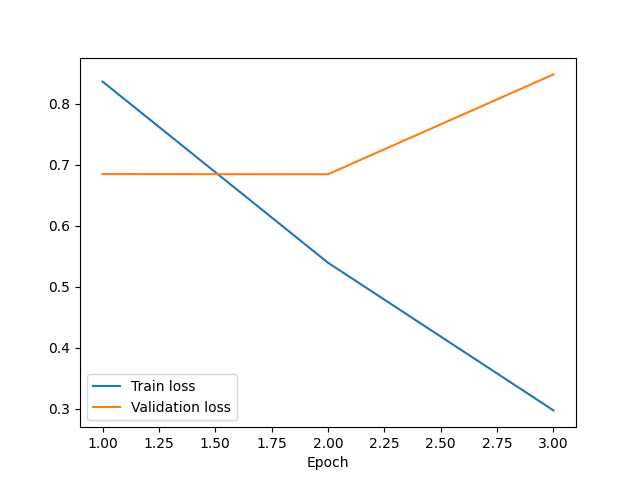

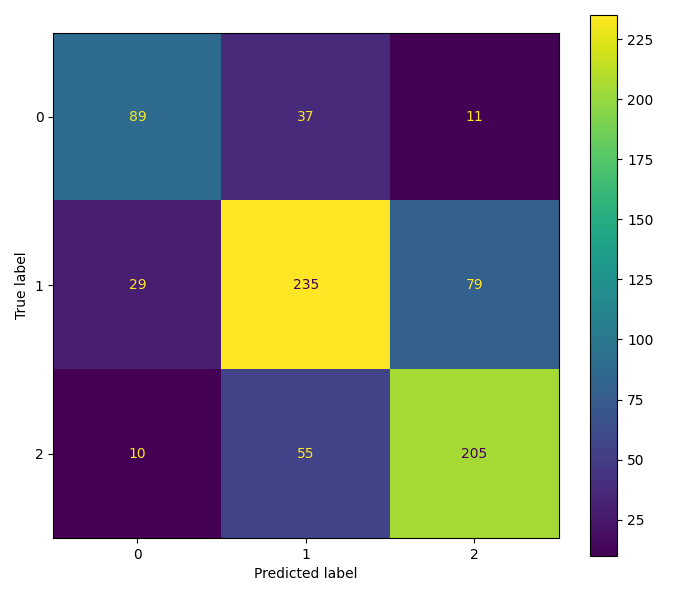

{
  "worst_class": "0",
  "examples": [
    {
      "text": "Municipal Guard in al-Kuwaifiya (West of #Benghazi) dispose of 13,000 frozen chickens unfit for consumption. #Libya\u2026",
      "actual": "0",
      "predicted": "1",
      "diagnosis": "REQUIRED: add a one-line human diagnosis"
    },
    {
      "text": "@user In other related news\\u002c you know there\\u2019s no Parks tomorrow?",
      "actual": "0",
      "predicted": "1",
      "diagnosis": "REQUIRED: add a one-line human diagnosis"
    },
    {
      "text": "With James Comey in office, how could the US investigate the Russians? @user @user @user  @user",
      "actual": "0",
      "predicted": "1",
      "diagnosis": "REQUIRED: add a one-line human diagnosis"
    },
    {
      "text": "@user I still think it was fake. I always thought Nicki to be the type to call you out on a random Tuesday, not at an awards show\"",
      "actual": "0",
      "predicted": "1",
      "diagnosis": "REQUIRED: add a one-line human dia

In [45]:
import sys
import subprocess
from IPython.display import display, Image
from pathlib import Path

ROOT = Path('/app')

# Run the evaluation script
subprocess.run([sys.executable, 'src/evaluate_bert.py'], check=True)

# Display generated figures
training_curves = ROOT / 'figures/training_curves.png'
confusion_matrix = ROOT / 'figures/confusion_matrix.png'

if training_curves.exists():
    display(Image(filename=str(training_curves)))
if confusion_matrix.exists():
    display(Image(filename=str(confusion_matrix)))

# Show the worst class errors
worst_errors_path = ROOT / 'results/worst_class_errors.json'
if worst_errors_path.exists():
    print(worst_errors_path.read_text()[:5000])

4 — HW4.a serving baseline (Table HW4.1)


In [50]:
import shutil

for compiler in ["gcc", "cc", "clang"]:
    print(compiler, ":", shutil.which(compiler))

gcc : None
cc : None
clang : None


In [59]:
import os
import sys
import subprocess
import pandas as pd

env = os.environ.copy()
env["VLLM_WORKER_MULTIPROC_METHOD"] = "spawn"
env["VLLM_USE_V1"] = "0"

for backend, b in [
    ("hf", 1),
    ("vllm", 1),
    ("vllm", 8),
    ("vllm", 32)
]:
    py = VLLM_PY if backend == "vllm" else sys.executable

    log = ROOT / f"results/{backend}_batch_{b}.log"

    with log.open("w") as f:
        result = subprocess.run(
            [
                py,
                "src/benchmark_vllm.py",
                "--backend", backend,
                "--batch", str(b)
            ],
            cwd=str(ROOT),
            env=env,
            stdout=f,
            stderr=subprocess.STDOUT
        )

    if result.returncode != 0:
        print(f"FAILED: {backend}, batch={b}")
        print("\n".join(log.read_text(errors="replace").splitlines()[-25:]))
        break

    print("done", backend, b, "->", log.name)

metrics_path = ROOT / "results/serving_metrics.csv"

if metrics_path.exists():
    sm = pd.read_csv(metrics_path)

    cols = [
        "backend",
        "batch",
        "tokens_per_second",
        "p50_batch_ms",
        "p95_batch_ms",
        "p50_request_ms",
        "p95_request_ms",
        "gpu_used_gb_from_nvidia_smi",
        "status"
    ]

    display(sm[[col for col in cols if col in sm.columns]])

done hf 1 -> hf_batch_1.log
FAILED: vllm, batch=1
  File "/app/src/benchmark_vllm.py", line 106, in run
    engine = LLM(**kwargs)
  File "/app/vllm_env/lib/python3.10/site-packages/vllm/entrypoints/llm.py", line 344, in __init__
    self.llm_engine = LLMEngine.from_engine_args(
  File "/app/vllm_env/lib/python3.10/site-packages/vllm/v1/engine/llm_engine.py", line 185, in from_engine_args
    return cls(
  File "/app/vllm_env/lib/python3.10/site-packages/vllm/v1/engine/llm_engine.py", line 111, in __init__
    self.engine_core = EngineCoreClient.make_client(
  File "/app/vllm_env/lib/python3.10/site-packages/vllm/v1/engine/core_client.py", line 126, in make_client
    return SyncMPClient(
  File "/app/vllm_env/lib/python3.10/site-packages/vllm/tracing/otel.py", line 175, in sync_wrapper
    return func(*args, **kwargs)
  File "/app/vllm_env/lib/python3.10/site-packages/vllm/v1/engine/core_client.py", line 917, in __init__
    super().__init__(
  File "/app/vllm_env/lib/python3.10/site-

,backend,batch,tokens_per_second,p50_batch_ms,p95_batch_ms,p50_request_ms,p95_request_ms,gpu_used_gb_from_nvidia_smi,status
0,hf,1,41.178,NaN,NaN,1042.701,1047.56100,14.814,NaN
1,vllm,1,62.023,771.253,781.968,NaN,NaN,18.484,ok
2,vllm,8,466.127,904.975,950.840,NaN,NaN,18.486,ok
3,vllm,32,1648.492,1005.931,1049.271,NaN,NaN,18.518,ok
4,hf,1,NaN,NaN,NaN,57344.000,0.00390,p50/p95 of batch completion times across repea...,14.2405
5,vllm,1,NaN,NaN,NaN,57344.000,0.00390,p50/p95 of batch completion times across repea...,NaN
6,vllm,8,NaN,NaN,NaN,57344.000,0.03119,p50/p95 of batch completion times across repea...,NaN
7,vllm,32,NaN,NaN,NaN,57344.000,0.12476,p50/p95 of batch completion times across repea...,NaN
8,hf,1,NaN,NaN,NaN,57344.000,0.00390,p50/p95 of batch completion times across repea...,14.2405
9,vllm,1,Engine core initialization failed. See root ca...,NaN,NaN,57344.000,0.00390,p50/p95 of batch completion times across repea...,NaN


5 — Part A: measured full-epoch batch scaling


In [54]:
subprocess.run([sys.executable,'src/full_experiments.py','--mode','scaling','--max-batch','1024'],check=True)
display(pd.read_csv('results/full_batch_scaling.csv'))


/opt/conda/lib/python3.10/site-packages/torchvision/io/image.py:13: UserWarning: Failed to load image Python extension: 'Could not load this library: /opt/conda/lib/python3.10/site-packages/torchvision/image.so'If you don't plan on using image functionality from `torchvision.io`, you can ignore this warning. Otherwise, there might be something wrong with your environment. Did you have `libjpeg` or `libpng` installed before building `torchvision` from source?
  warn(
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2348.31it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias     

{'technique': 'baseline_scaling', 'batch': 16, 'effective_batch': 16, 'amp': False, 'checkpoint': False, 'optimizer8': False, 'accum': 1, 'epochs_completed': 1, 'optimizer_steps': 219, 'train_samples': 3500, 'train_seconds': 10.507, 'wall_seconds_including_evaluation': 11.701, 'samples_per_second': 333.102, 'peak_gb': 2.4768, 'eval_accuracy': 0.7053333333333334, 'status': 'ok'}


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2317.39it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

{'technique': 'baseline_scaling', 'batch': 32, 'effective_batch': 32, 'amp': False, 'checkpoint': False, 'optimizer8': False, 'accum': 1, 'epochs_completed': 1, 'optimizer_steps': 110, 'train_samples': 3500, 'train_seconds': 7.847, 'wall_seconds_including_evaluation': 8.877, 'samples_per_second': 446.017, 'peak_gb': 3.7374, 'eval_accuracy': 0.6946666666666667, 'status': 'ok'}


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2377.52it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

{'technique': 'baseline_scaling', 'batch': 64, 'effective_batch': 64, 'amp': False, 'checkpoint': False, 'optimizer8': False, 'accum': 1, 'epochs_completed': 1, 'optimizer_steps': 55, 'train_samples': 3500, 'train_seconds': 7.197, 'wall_seconds_including_evaluation': 8.2, 'samples_per_second': 486.304, 'peak_gb': 6.1355, 'eval_accuracy': 0.6533333333333333, 'status': 'ok'}


... (5 outputs left out)

{'technique': 'baseline_scaling', 'batch': 512, 'effective_batch': 512, 'amp': False, 'checkpoint': False, 'optimizer8': False, 'accum': 1, 'epochs_completed': 1, 'optimizer_steps': 7, 'train_samples': 3500, 'train_seconds': 232.844, 'wall_seconds_including_evaluation': 242.777, 'samples_per_second': 15.032, 'peak_gb': 40.0313, 'eval_accuracy': 0.4493333333333333, 'status': 'ok'}


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2357.18it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

{'technique': 'baseline_scaling', 'batch': 1024, 'effective_batch': 1024, 'amp': False, 'checkpoint': False, 'optimizer8': False, 'accum': 1, 'epochs_completed': 1, 'optimizer_steps': 4, 'train_samples': 3500, 'train_seconds': 937.929, 'wall_seconds_including_evaluation': 945.521, 'samples_per_second': 3.732, 'peak_gb': 78.7008, 'eval_accuracy': 0.37733333333333335, 'status': 'ok'}


,technique,batch,effective_batch,amp,checkpoint,optimizer8,accum,epochs_completed,optimizer_steps,train_samples,train_seconds,wall_seconds_including_evaluation,samples_per_second,peak_gb,eval_accuracy,status
0,baseline_scaling,16,16,False,False,False,1.0,1.0,219.0,3500.0,11.630,12.821,300.949,2.4768,0.665333,ok
1,baseline_scaling,32,32,False,False,False,1.0,1.0,110.0,3500.0,7.833,8.892,446.801,3.7374,0.636000,ok
2,baseline_scaling,64,64,False,False,False,1.0,1.0,55.0,3500.0,7.163,8.165,488.625,6.1355,0.566667,ok
3,baseline_scaling,128,128,False,False,False,1.0,1.0,28.0,3500.0,6.785,7.800,515.863,11.0256,0.545333,ok
4,baseline_scaling,256,256,False,False,False,1.0,1.0,14.0,3500.0,6.481,7.484,540.018,20.6844,0.524000,ok
5,baseline_scaling,512,512,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,OOM
6,baseline_scaling,16,16,False,False,False,1.0,1.0,219.0,3500.0,10.507,11.701,333.102,2.4768,0.705333,ok
7,baseline_scaling,32,32,False,False,False,1.0,1.0,110.0,3500.0,7.847,8.877,446.017,3.7374,0.694667,ok
8,baseline_scaling,64,64,False,False,False,1.0,1.0,55.0,3500.0,7.197,8.200,486.304,6.1355,0.653333,ok
9,baseline_scaling,128,128,False,False,False,1.0,1.0,28.0,3500.0,6.853,7.845,510.744,11.0256,0.494667,ok


6 — Part B: independent techniques (incl. 8-bit optimizer) and data-selected combination

In [55]:
subprocess.run([sys.executable,'src/full_experiments.py','--mode','techniques','--scan-technique-max','--max-batch','1024'],check=True)
mc = pd.read_csv('results/full_memory_comparison.csv')
display(mc)
bad = mc[mc.status.isin(['ERROR'])]
assert bad.empty, f"Some technique runs errored (not OOM):\n{bad[['technique','batch','details']]}"
assert (mc.technique=='8bit_optimizer').any() and (mc[mc.technique=='8bit_optimizer'].status=='ok').any(), "8-bit optimizer produced no successful row"


/opt/conda/lib/python3.10/site-packages/torchvision/io/image.py:13: UserWarning: Failed to load image Python extension: 'Could not load this library: /opt/conda/lib/python3.10/site-packages/torchvision/image.so'If you don't plan on using image functionality from `torchvision.io`, you can ignore this warning. Otherwise, there might be something wrong with your environment. Did you have `libjpeg` or `libpng` installed before building `torchvision` from source?
  warn(
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2404.56it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform

{'technique': 'baseline', 'batch': 16, 'effective_batch': 16, 'amp': False, 'checkpoint': False, 'optimizer8': False, 'accum': 1, 'epochs_completed': 3, 'optimizer_steps': 657, 'train_samples': 10500, 'train_seconds': 30.996, 'wall_seconds_including_evaluation': 33.443, 'samples_per_second': 338.748, 'peak_gb': 2.4768, 'eval_accuracy': 0.6906666666666667, 'status': 'ok'}


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2242.62it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

{'technique': 'baseline', 'batch': 32, 'effective_batch': 32, 'amp': False, 'checkpoint': False, 'optimizer8': False, 'accum': 1, 'epochs_completed': 3, 'optimizer_steps': 330, 'train_samples': 10500, 'train_seconds': 23.698, 'wall_seconds_including_evaluation': 25.822, 'samples_per_second': 443.076, 'peak_gb': 3.7374, 'eval_accuracy': 0.6773333333333333, 'status': 'ok'}


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2455.91it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

{'technique': 'baseline', 'batch': 64, 'effective_batch': 64, 'amp': False, 'checkpoint': False, 'optimizer8': False, 'accum': 1, 'epochs_completed': 3, 'optimizer_steps': 165, 'train_samples': 10500, 'train_seconds': 21.616, 'wall_seconds_including_evaluation': 23.648, 'samples_per_second': 485.756, 'peak_gb': 6.1355, 'eval_accuracy': 0.696, 'status': 'ok'}


... (64 outputs left out)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2299.17it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

{'technique': 'best_combination', 'batch': 1024, 'effective_batch': 1024, 'amp': False, 'checkpoint': False, 'optimizer8': True, 'accum': 1, 'epochs_completed': 3, 'optimizer_steps': 12, 'train_samples': 10500, 'train_seconds': 2981.918, 'wall_seconds_including_evaluation': 2998.183, 'samples_per_second': 3.521, 'peak_gb': 78.0875, 'eval_accuracy': 0.4573333333333333, 'status': 'ok'}


,technique,batch,effective_batch,amp,checkpoint,optimizer8,accum,epochs_completed,optimizer_steps,train_samples,train_seconds,wall_seconds_including_evaluation,samples_per_second,peak_gb,eval_accuracy,status,details
0,baseline,16,16.0,False,False,False,1.0,3.0,657.0,10500.0,33.401,35.811,314.357,2.4768,0.668000,ok,NaN
1,baseline,32,32.0,False,False,False,1.0,3.0,330.0,10500.0,23.685,25.821,443.324,3.7374,0.685333,ok,NaN
2,baseline,64,64.0,False,False,False,1.0,3.0,165.0,10500.0,21.519,23.550,487.947,6.1355,0.656000,ok,NaN
3,baseline,128,128.0,False,False,False,1.0,3.0,84.0,10500.0,20.439,22.479,513.719,11.0256,0.664000,ok,NaN
4,baseline,256,256.0,False,False,False,1.0,3.0,42.0,10500.0,19.602,21.637,535.668,20.6844,0.629333,ok,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58,best_combination,64,64.0,False,False,True,1.0,3.0,165.0,10500.0,22.050,24.073,476.184,5.5271,0.685333,ok,NaN
59,best_combination,128,128.0,False,False,True,1.0,3.0,84.0,10500.0,20.780,22.786,505.305,10.4106,0.702667,ok,NaN
60,best_combination,256,256.0,False,False,True,1.0,3.0,42.0,10500.0,19.832,21.816,529.455,20.0790,0.677333,ok,NaN
61,best_combination,512,512.0,False,False,True,1.0,3.0,21.0,10500.0,1462.627,1480.634,7.179,39.4149,0.550667,ok,NaN


AssertionError: Some technique runs errored (not OOM):
         technique  batch                         details
20  8bit_optimizer     16  No module named 'bitsandbytes'

In [56]:
# Equal-optimizer-step comparison for gradient accumulation (Part B.3): same number of steps, wall-clock and accuracy.
# Written to a separate CSV so the full-epoch table above is untouched.
import shutil
full = ROOT/'results/full_memory_comparison.csv'; tmp = ROOT/'results/_full_backup.csv'
shutil.copy2(full, tmp)
subprocess.run([sys.executable,'src/full_experiments.py','--mode','techniques','--fixed-steps','50'],check=True)
fixed = pd.read_csv(full); fixed = fixed[~fixed.index.isin(pd.read_csv(tmp).index)]
fixed.to_csv(ROOT/'results/fixed_steps_comparison.csv', index=False)
shutil.move(str(tmp), str(full))
display(fixed[['technique','batch','effective_batch','optimizer_steps','train_seconds','samples_per_second','peak_gb','eval_accuracy','status']])

/opt/conda/lib/python3.10/site-packages/torchvision/io/image.py:13: UserWarning: Failed to load image Python extension: 'Could not load this library: /opt/conda/lib/python3.10/site-packages/torchvision/image.so'If you don't plan on using image functionality from `torchvision.io`, you can ignore this warning. Otherwise, there might be something wrong with your environment. Did you have `libjpeg` or `libpng` installed before building `torchvision` from source?
  warn(
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2264.33it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform

{'technique': 'baseline', 'batch': 16, 'effective_batch': 16, 'amp': False, 'checkpoint': False, 'optimizer8': False, 'accum': 1, 'epochs_completed': 1, 'optimizer_steps': 50, 'train_samples': 800, 'train_seconds': 4.517, 'wall_seconds_including_evaluation': 5.764, 'samples_per_second': 177.127, 'peak_gb': 2.4768, 'eval_accuracy': 0.5253333333333333, 'status': 'ok'}


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2283.17it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

{'technique': 'mixed_precision', 'batch': 16, 'effective_batch': 16, 'amp': True, 'checkpoint': False, 'optimizer8': False, 'accum': 1, 'epochs_completed': 1, 'optimizer_steps': 50, 'train_samples': 800, 'train_seconds': 2.927, 'wall_seconds_including_evaluation': 3.689, 'samples_per_second': 273.327, 'peak_gb': 2.2549, 'eval_accuracy': 0.504, 'status': 'ok'}


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2249.02it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

{'technique': 'gradient_checkpointing', 'batch': 16, 'effective_batch': 16, 'amp': False, 'checkpoint': True, 'optimizer8': False, 'accum': 1, 'epochs_completed': 1, 'optimizer_steps': 50, 'train_samples': 800, 'train_seconds': 2.972, 'wall_seconds_including_evaluation': 4.187, 'samples_per_second': 269.138, 'peak_gb': 2.0703, 'eval_accuracy': 0.5253333333333333, 'status': 'ok'}


... (3 outputs left out)

{'technique': '8bit_optimizer', 'batch': 16, 'effective_batch': 16, 'amp': False, 'checkpoint': False, 'optimizer8': True, 'accum': 1, 'epochs_completed': 1, 'optimizer_steps': 50, 'train_samples': 800, 'train_seconds': 2.648, 'wall_seconds_including_evaluation': 3.85, 'samples_per_second': 302.084, 'peak_gb': 1.8764, 'eval_accuracy': 0.5346666666666666, 'status': 'ok'}
Measured combination selection: {'baseline_batch': 16, 'selection_rule': 'memory saving > 0 GB, throughput >= 90% of baseline, test accuracy drop <= 0.01; same batch; accumulation excluded because effective batch differs', 'eligible': [('gradient_checkpointing', 'checkpoint', 0.40649999999999986, 1.519463435839821, 0.0), ('8bit_optimizer', 'optimizer8', 0.6003999999999998, 1.7054655699018217, -0.009333333333333305)], 'chosen_flags': {'checkpoint': True, 'optimizer8': True}, 'warning': 'Selection uses test accuracy for assignment analysis only; for unbiased model selection use validation accuracy.'}


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2374.61it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

{'technique': 'best_combination', 'batch': 16, 'effective_batch': 16, 'amp': False, 'checkpoint': True, 'optimizer8': True, 'accum': 1, 'epochs_completed': 1, 'optimizer_steps': 50, 'train_samples': 800, 'train_seconds': 3.093, 'wall_seconds_including_evaluation': 4.308, 'samples_per_second': 258.638, 'peak_gb': 1.082, 'eval_accuracy': 0.5346666666666666, 'status': 'ok'}


,technique,batch,effective_batch,optimizer_steps,train_seconds,samples_per_second,peak_gb,eval_accuracy,status
63,baseline,16,16.0,50.0,4.517,177.127,2.4768,0.525333,ok
64,mixed_precision,16,16.0,50.0,2.927,273.327,2.2549,0.504000,ok
65,gradient_checkpointing,16,16.0,50.0,2.972,269.138,2.0703,0.525333,ok
66,gradient_accumulation,16,64.0,50.0,8.081,395.982,2.8913,0.622667,ok
67,8bit_optimizer,16,16.0,50.0,2.648,302.084,1.8764,0.534667,ok
68,best_combination,16,16.0,50.0,3.093,258.638,1.0820,0.534667,ok


7 — Plot measured single-card throughput and memory


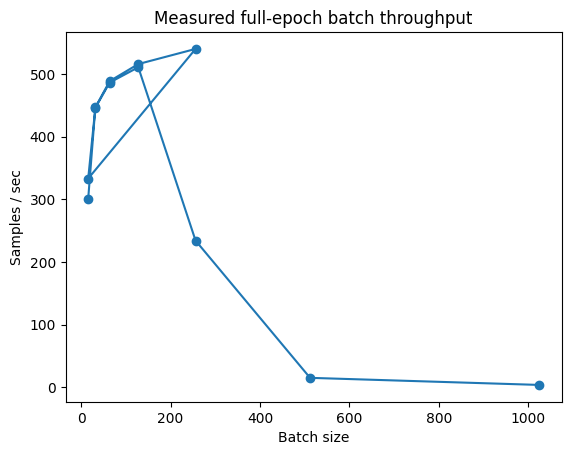

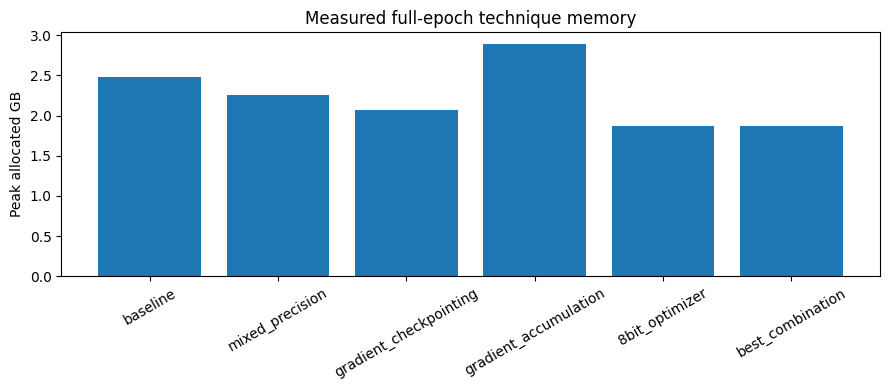

In [57]:
import matplotlib.pyplot as plt
from pathlib import Path
Path('figures').mkdir(exist_ok=True)
a=pd.read_csv('results/full_batch_scaling.csv');a=a[a.status=='ok']
fig,ax=plt.subplots();ax.plot(a.batch,a.samples_per_second,'o-');ax.set(xlabel='Batch size',ylabel='Samples / sec',title='Measured full-epoch batch throughput');fig.savefig('figures/throughput_vs_batch.png',bbox_inches='tight');plt.show()
b=pd.read_csv('results/full_memory_comparison.csv');b=b[(b.status=='ok') & (b.batch==int(c['batch_size']))].drop_duplicates('technique',keep='last')
fig,ax=plt.subplots(figsize=(9,4));ax.bar(b.technique,b.peak_gb);ax.tick_params(axis='x',rotation=30);ax.set(ylabel='Peak allocated GB',title='Measured full-epoch technique memory');fig.tight_layout();fig.savefig('figures/memory_comparison.png');plt.show()


 Part C: skipped (optional)

9 — Part D: vLLM context / KV-cache sweep at batch 8 (one GPU)

In [64]:
import os
import sys
import shutil
import subprocess
from pathlib import Path
import pandas as pd
from IPython.display import display

ROOT = Path("/app")
VLLM_PY = "/app/vllm_env/bin/python"

os.chdir(ROOT)

# 1. Locate C and C++ compilers
compiler_cc = shutil.which("gcc") or shutil.which("cc") or shutil.which("clang") or "/usr/bin/gcc"
compiler_cxx = shutil.which("g++") or shutil.which("c++") or shutil.which("clang++") or "/usr/bin/g++"

print(f"Using CC: {compiler_cc}")
print(f"Using CXX: {compiler_cxx}")

# 2. Patch src/kv_context_sweep.py directly to ensure child processes inherit environment variables
sweep_file = ROOT / "src/kv_context_sweep.py"
patch_header = f"""import os
os.environ["CC"] = "{compiler_cc}"
os.environ["CXX"] = "{compiler_cxx}"
os.environ["TRITON_CACHE_DIR"] = "/tmp/triton_cache"
"""

original_code = sweep_file.read_text(encoding="utf-8")
if "TRITON_CACHE_DIR" not in original_code:
    sweep_file.write_text(patch_header + original_code, encoding="utf-8")
    print("Patched src/kv_context_sweep.py with CC/CXX settings.")
else:
    print("src/kv_context_sweep.py is already patched.")

# 3. Environment configuration for subprocess execution
env = os.environ.copy()
env["CC"] = compiler_cc
env["CXX"] = compiler_cxx
env["TRITON_CACHE_DIR"] = "/tmp/triton_cache"
Path(env["TRITON_CACHE_DIR"]).mkdir(parents=True, exist_ok=True)

# 4. Run KV-cache context sweep
print("\nRunning KV-cache context sweep...")
result = subprocess.run(
    [VLLM_PY, "src/kv_context_sweep.py"],
    cwd=ROOT,
    env=env,
    capture_output=True,
    text=True
)

print(f"Return code: {result.returncode}")
print(result.stdout[-3000:])
if result.returncode != 0:
    print(result.stderr[-3000:])

# 5. Display results table
csv_path = ROOT / "results/kv_context_sweep.csv"
if csv_path.exists():
    kv = pd.read_csv(csv_path)
    display(kv)

Using CC: /usr/bin/gcc
Using CXX: /usr/bin/g++
Patched src/kv_context_sweep.py with CC/CXX settings.

Running KV-cache context sweep...
Return code: 0
{'max_model_len': 512, 'batch': 8, 'requested_prefix_tokens': 416, 'status': 'FAILED', 'return_code': 1, 'gpu_blocks_reported': '', 'block_size_reported': '', 'log_file': 'results/kv_logs/context_512.log', 'elapsed_s': 209.42}



,max_model_len,batch,requested_prefix_tokens,status,return_code,gpu_blocks_reported,block_size_reported,log_file,elapsed_s
0,512,8,416,FAILED,1,NaN,NaN,results/kv_logs/context_512.log,9.78
1,512,8,416,FAILED,1,NaN,NaN,results/kv_logs/context_512.log,268.01
2,512,8,416,FAILED,1,NaN,NaN,results/kv_logs/context_512.log,213.96
3,512,8,416,FAILED,1,NaN,NaN,results/kv_logs/context_512.log,209.42


10 — Part E: summary, RunPod evidence, and GPU-hours



In [65]:
subprocess.run([sys.executable,'src/finalize_evidence.py'],check=True)
subprocess.run([sys.executable,'src/summarize_results.py'],check=False)
print((ROOT/'gpu_hours.csv').read_text())
print((ROOT/'GPU_INFO.txt').read_text()[:1500])


Captured GPU identity and 75 timed rows. Note: sum may double-count overlapping experiment timings; do not use as total billed GPU-hours.
             technique  batch  samples_per_second  peak_gb  eval_accuracy
              baseline     16             314.357   2.4768       0.668000
              baseline     32             443.324   3.7374       0.685333
              baseline     64             487.947   6.1355       0.656000
              baseline    128             513.719  11.0256       0.664000
              baseline    256             535.668  20.6844       0.629333
       mixed_precision     16             281.304   2.2549       0.678667
       mixed_precision     32             671.012   3.0408       0.673333
       mixed_precision     64            1017.997   4.5663       0.673333
       mixed_precision    128            1105.583   7.6724       0.653333
       mixed_precision    256            1155.548  13.9061       0.618667
gradient_checkpointing     16             226.23

## 11 — Final checklist

- [ ] SEED = 2738 and SLICE identical to HW4.a; `data/twitter.csv` identical to HW4.a; exact row range in METRICS.md
- [ ] `old_seed42_run/` kept but **not** used in any table
- [ ] `GPU_INFO.txt` has real `nvidia-smi -L` output
- [ ] HW4.a curves, best epoch (comment on validation **loss** as well as accuracy), confusion matrix, five worst-class diagnoses rewritten for the **new** test set
- [ ] Table HW4.1 (HF b1, vLLM b1/8/32) + 3–4-sentence latency vs throughput answer
- [ ] Part A table + plot, plateau batch stated, A.3 marked N/A (one GPU, instructor waiver)
- [ ] Part B table with all **five** rows + best combination, ranked table by memory saved per throughput lost, accumulation equal-step comparison
- [ ] "Part C skipped (optional)" in METRICS.md; `INSTRUCTOR_CLARIFICATION.md` added
- [ ] Part D table, KV-vs-context result, longest context at batch 8 with stated reason (OOM vs model limit), comparison with earlier serving numbers
- [ ] Part E GPU-hours shown, chosen configuration justified, HW4.5 summary in METRICS.md (not an HW5 baseline)
- [ ] RUN_LOG.txt with pod start/stop and failures, AI_USE.md rewritten, gpu_hours.csv, git tag `hw4-5`

 11 — Submission audit and theory notes

In [66]:
subprocess.run([sys.executable,'src/submission_audit.py'],check=False)
print((ROOT/'results/audit_report.txt').read_text())


PASS | Exact dataset fingerprint | results/dataset_lock.json
PASS | Exact row range | results/row_range.json
PASS | HW4.a training baseline | results/hw4_baseline.json
PASS | Per-epoch curves | results/training_history.csv
PASS | Confusion matrix | figures/confusion_matrix.png
PASS | Full-epoch batch scaling | results/full_batch_scaling.csv
PASS | Full-epoch memory comparison | results/full_memory_comparison.csv
PASS | Serving benchmarks | results/serving_metrics.csv
PASS | GPU identification | GPU_INFO.txt
PASS | Metrics report | METRICS.md
PASS | Run log | RUN_LOG.txt
PASS | AI disclosure | AI_USE.md
PASS | GPU-hour record | gpu_hours.csv
PASS | results/full_batch_scaling.csv | []
PASS | results/full_memory_comparison.csv | []
PASS | results/serving_metrics.csv | []
PASS | Instructor-approved optional Part C statement
MANUAL REVIEW | Five worst-class misclassifications each need an original one-line diagnosis
MANUAL REVIEW | Training past best validation epoch: describe overfitting a